### **Digital Image Processing**

***Practical File***

***Arjun***
***8535***

## ***Practical 1***

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

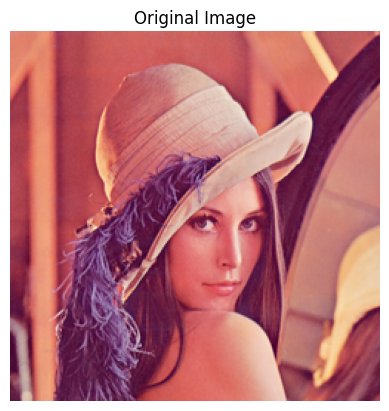

In [9]:
img =  cv2.imread('./Lenna_test_image.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('off')
plt.show()

In [10]:
import os
print(os.getcwd())


/content


In [11]:
print(os.listdir())

['.config', 'Lenna_test_image.png', '.ipynb_checkpoints', 'sample_data']


### Practical 1: Basic Image Operations

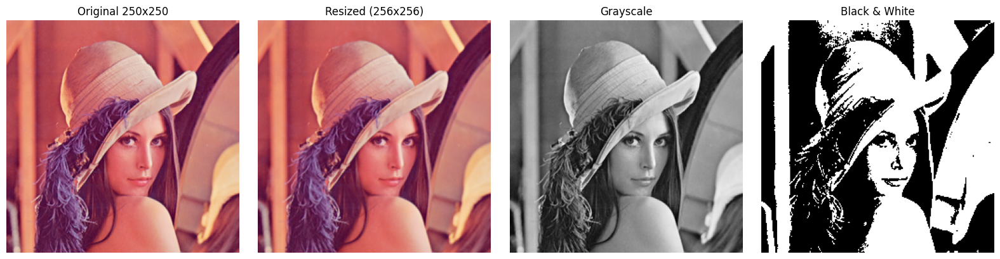

In [12]:
# 1.b. Resize a given image
# Let's resize the image to 256x256
height, width = img_rgb.shape[:2]
resized_img = cv2.resize(img_rgb, (256, 256))

# 1.c. Convert color image to gray-scale
gray_img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# 1.d. Convert to black & white (binary threshold)
_, bw_img = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

# Plotting results
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_rgb)
axes[0].set_title(f'Original {width}x{height}')
axes[0].axis('off')

axes[1].imshow(resized_img)
axes[1].set_title('Resized (256x256)')
axes[1].axis('off')

axes[2].imshow(gray_img, cmap='gray')
axes[2].set_title('Grayscale')
axes[2].axis('off')

axes[3].imshow(bw_img, cmap='gray')
axes[3].set_title('Black & White')
axes[3].axis('off')

plt.tight_layout()
plt.show()

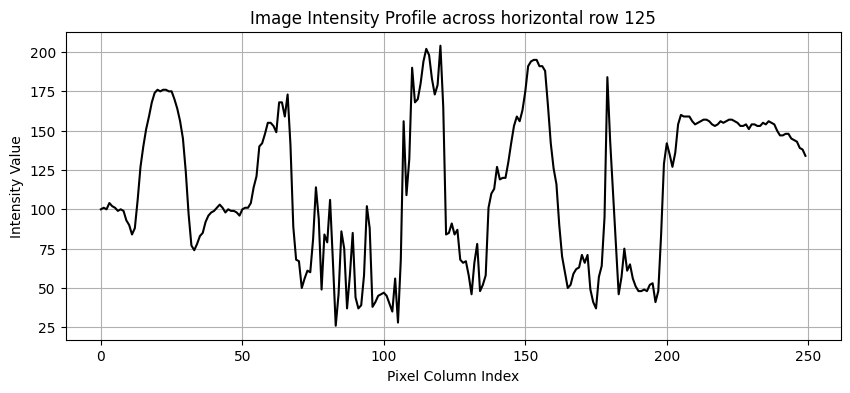

In [13]:
# 1.f (part 1). Draw the image profile (intensity profile along a line)
# Let's plot the intensity profile across a horizontal line in the middle of the grayscale image
row_idx = gray_img.shape[0] // 2
profile = gray_img[row_idx, :]

plt.figure(figsize=(10, 4))
plt.plot(profile, color='black')
plt.title(f'Image Intensity Profile across horizontal row {row_idx}')
plt.xlabel('Pixel Column Index')
plt.ylabel('Intensity Value')
plt.grid(True)
plt.show()

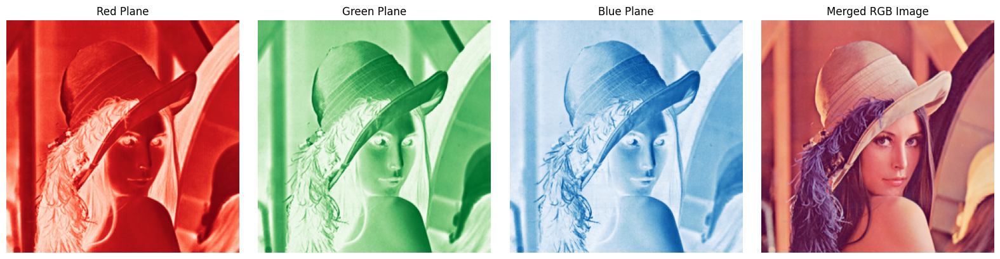

In [14]:
# 1.e. Separate a given color image into R, G & B planes
R, G, B = cv2.split(img_rgb)

# 1.f (part 2). Create a color image using separate three R, G and B planes
merged_img = cv2.merge([R, G, B])

# Displaying the channels
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(R, cmap='Reds')
axes[0].set_title('Red Plane')
axes[0].axis('off')

axes[1].imshow(G, cmap='Greens')
axes[1].set_title('Green Plane')
axes[1].axis('off')

axes[2].imshow(B, cmap='Blues')
axes[2].set_title('Blue Plane')
axes[2].axis('off')

axes[3].imshow(merged_img)
axes[3].set_title('Merged RGB Image')
axes[3].axis('off')

plt.tight_layout()
plt.show()

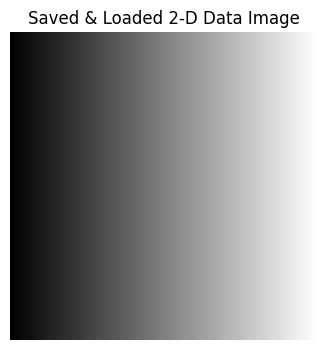

In [15]:
# 1.g. Write given 2-D data in image file
# Generating a synthetic 2D numpy array (e.g., a spatial gradient)
x = np.linspace(0, 255, 256, dtype=np.uint8)
# Create a 2D meshgrid
gradient_2d = np.tile(x, (256, 1))

# Save the 2D array as an image file
cv2.imwrite('gradient_output.png', gradient_2d)

# Read back and verify
saved_img = cv2.imread('gradient_output.png', cv2.IMREAD_GRAYSCALE)
plt.figure(figsize=(4, 4))
plt.imshow(saved_img, cmap='gray')
plt.title('Saved & Loaded 2-D Data Image')
plt.axis('off')
plt.show()

### Practical 2: Point Processing
* a. Negative Image
* b. Flip Image
* c. Thresholding
* d. Contrast stretching

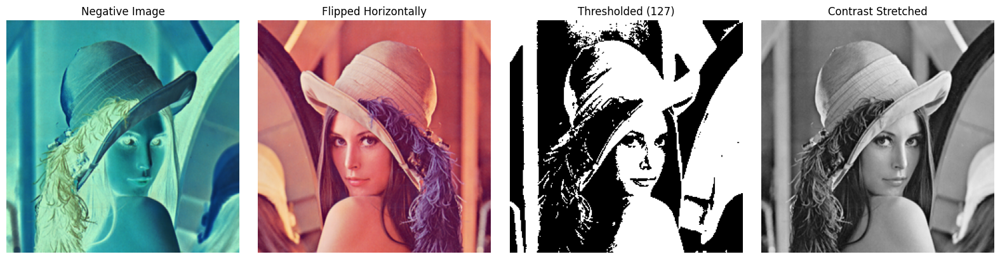

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = cv2.imread('./Lenna_test_image.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray_img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# 2.a. Obtain Negative image
negative_img = 255 - img_rgb

# 2.b. Obtain Flip image (horizontal)
flip_horiz = cv2.flip(img_rgb, 1)

# 2.c. Thresholding
_, thresh_img = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

# 2.d. Contrast stretching
min_val, max_val = np.min(gray_img), np.max(gray_img)
contrast_stretched = ((gray_img - min_val) / (max_val - min_val) * 255).astype(np.uint8)

# Plotting results
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(negative_img)
axes[0].set_title('Negative Image')
axes[0].axis('off')

axes[1].imshow(flip_horiz)
axes[1].set_title('Flipped Horizontally')
axes[1].axis('off')

axes[2].imshow(thresh_img, cmap='gray')
axes[2].set_title('Thresholded (127)')
axes[2].axis('off')

axes[3].imshow(contrast_stretched, cmap='gray')
axes[3].set_title('Contrast Stretched')
axes[3].axis('off')

plt.tight_layout()
plt.show()

### Practical 3: Image Arithmetic Operations
* a. Addition of two images
* b. Subtraction of two images
* c. Mean value calculation
* d. Brightness variation by shifting the mean value

Mean value of the original image: 127.73


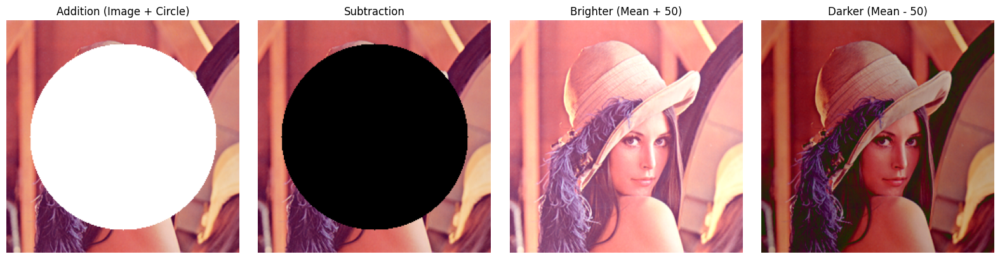

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure image is loaded
img = cv2.imread('./Lenna_test_image.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Create a second image with the same dimensions
height, width, channels = img_rgb.shape
second_image = np.zeros((height, width, channels), dtype=np.uint8)
cv2.circle(second_image, (width//2, height//2), 100, (255, 255, 255), -1)

# 3.a. Addition of two images
added_img = cv2.add(img_rgb, second_image)

# 3.b. Subtract one image from other image
subtracted_img = cv2.subtract(img_rgb, second_image)

# 3.c. Calculate mean value of image
mean_val = np.mean(img_rgb)
print(f"Mean value of the original image: {mean_val:.2f}")

# 3.d. Different Brightness by changing mean value
bright_img = cv2.convertScaleAbs(img_rgb, alpha=1.0, beta=50)
dark_img = cv2.convertScaleAbs(img_rgb, alpha=1.0, beta=-50)

# Plotting results
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(added_img)
axes[0].set_title('Addition (Image + Circle)')
axes[0].axis('off')

axes[1].imshow(subtracted_img)
axes[1].set_title('Subtraction')
axes[1].axis('off')

axes[2].imshow(bright_img)
axes[2].set_title('Brighter (Mean + 50)')
axes[2].axis('off')

axes[3].imshow(dark_img)
axes[3].set_title('Darker (Mean - 50)')
axes[3].axis('off')

plt.tight_layout()
plt.show()

### Practical 4: Image Logical Operations
* a. AND operation
* b. OR operation
* c. Intersection
* d. Watermarking using XOR operation
* e. NOT operation

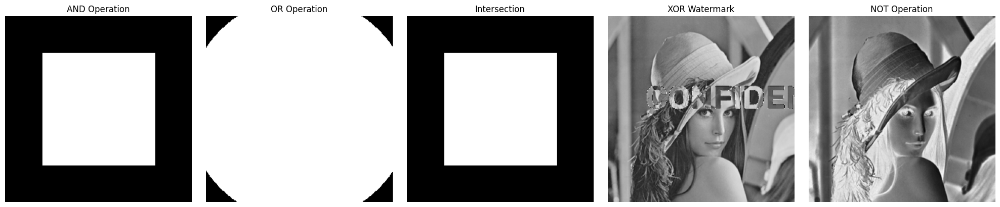

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure base image is loaded
img = cv2.imread('./Lenna_test_image.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray_img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
height, width = gray_img.shape

# Prepare black and white binary masks
mask1 = np.zeros((height, width), dtype=np.uint8)
cv2.rectangle(mask1, (50, 50), (width-50, height-50), 255, -1)

mask2 = np.zeros((height, width), dtype=np.uint8)
cv2.circle(mask2, (width//2, height//2), 150, 255, -1)

# 4.a. AND operation
and_op = cv2.bitwise_and(mask1, mask2)

# 4.b. OR operation
or_op = cv2.bitwise_or(mask1, mask2)

# 4.c. Intersection
intersection_op = and_op

# 4.d. Watermarking using XOR operation
watermark = np.zeros((height, width), dtype=np.uint8)
cv2.putText(watermark, "CONFIDENTIAL", (50, height//2), cv2.FONT_HERSHEY_SIMPLEX, 1.5, 255, 5, cv2.LINE_AA)
xor_watermarked = cv2.bitwise_xor(gray_img, watermark)

# 4.e. NOT operation
not_op = cv2.bitwise_not(gray_img)

# Plotting results
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(and_op, cmap='gray')
axes[0].set_title('AND Operation')
axes[0].axis('off')

axes[1].imshow(or_op, cmap='gray')
axes[1].set_title('OR Operation')
axes[1].axis('off')

axes[2].imshow(intersection_op, cmap='gray')
axes[2].set_title('Intersection')
axes[2].axis('off')

axes[3].imshow(xor_watermarked, cmap='gray')
axes[3].set_title('XOR Watermark')
axes[3].axis('off')

axes[4].imshow(not_op, cmap='gray')
axes[4].set_title('NOT Operation')
axes[4].axis('off')

plt.tight_layout()
plt.show()

### Practical 5: Histogram Calculation and Equalization
* a. Using inbuilt function (`cv2.calcHist`, `cv2.equalizeHist`)
* b. Without using inbuilt function (Manual calculation using numpy)

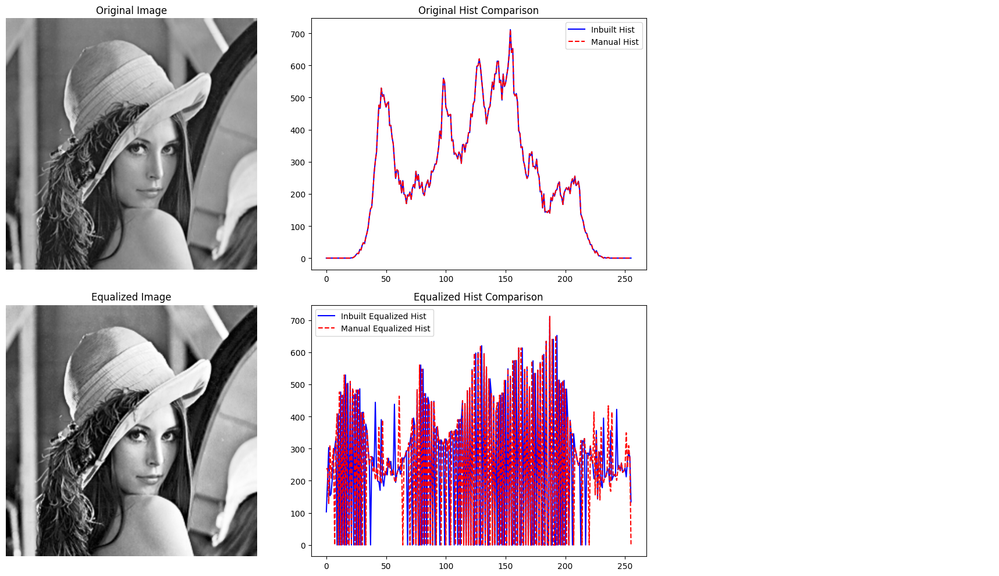

In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ensure base grayscale image is loaded
img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)

# --- 5.a. Using Inbuilt Functions ---
hist_inbuilt = cv2.calcHist([img_gray], [0], None, [256], [0, 256])
equalized_inbuilt = cv2.equalizeHist(img_gray)
hist_eq_inbuilt = cv2.calcHist([equalized_inbuilt], [0], None, [256], [0, 256])

# --- 5.b. Without Using Inbuilt Functions (Manual Implementation)---
hist_manual = np.zeros(256, dtype=int)
for pixel_val in img_gray.ravel():
    hist_manual[pixel_val] += 1

cdf = hist_manual.cumsum()
cdf_normalized = cdf * (255 / cdf[-1])
equalized_manual = cdf_normalized[img_gray].astype(np.uint8)

hist_eq_manual = np.zeros(256, dtype=int)
for pixel_val in equalized_manual.ravel():
    hist_eq_manual[pixel_val] += 1

# Plotting Comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes[0, 0].imshow(img_gray, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].plot(hist_inbuilt, color='blue', label='Inbuilt Hist')
axes[0, 1].plot(hist_manual, color='red', linestyle='dashed', label='Manual Hist')
axes[0, 1].set_title('Original Hist Comparison')
axes[0, 1].legend()
axes[0, 2].axis('off')

axes[1, 0].imshow(equalized_manual, cmap='gray')
axes[1, 0].set_title('Equalized Image')
axes[1, 0].axis('off')

axes[1, 1].plot(hist_eq_inbuilt, color='blue', label='Inbuilt Equalized Hist')
axes[1, 1].plot(hist_eq_manual, color='red', linestyle='dashed', label='Manual Equalized Hist')
axes[1, 1].set_title('Equalized Hist Comparison')
axes[1, 1].legend()
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Practical 6: Geometric Transformations on an Image
* a. Translation
* b. Scaling
* c. Rotation
* d. Shrinking
* e. Zooming

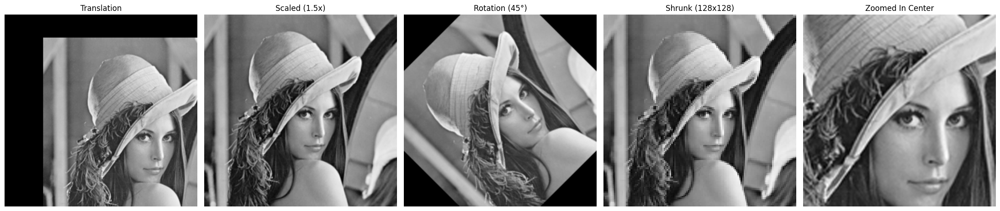

In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)
rows, cols = img_gray.shape

# 6.a. Translation (Shifting by tx=50, ty=30)
M_translation = np.float32([[1, 0, 50], [0, 1, 30]])
translated_img = cv2.warpAffine(img_gray, M_translation, (cols, rows))

# 6.b. Scaling
scaled_img = cv2.resize(img_gray, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)

# 6.c. Rotation (Rotate around center by 45 degrees)
M_rotation = cv2.getRotationMatrix2D((cols/2, rows/2), 45, 1)
rotated_img = cv2.warpAffine(img_gray, M_rotation, (cols, rows))

# 6.d. Shrinking
shrunk_img = cv2.resize(img_gray, (128, 128), interpolation=cv2.INTER_AREA)

# 6.e. Zooming
start_row, start_col = int(rows * 0.25), int(cols * 0.25)
end_row, end_col = int(rows * 0.75), int(cols * 0.75)
cropped_section = img_gray[start_row:end_row, start_col:end_col]
zoomed_img = cv2.resize(cropped_section, (cols, rows), interpolation=cv2.INTER_CUBIC)

# Displaying the transformations
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
axes[0].imshow(translated_img, cmap='gray')
axes[0].set_title('Translation')
axes[0].axis('off')

axes[1].imshow(scaled_img, cmap='gray')
axes[1].set_title('Scaled (1.5x)')
axes[1].axis('off')

axes[2].imshow(rotated_img, cmap='gray')
axes[2].set_title('Rotation (45°)')
axes[2].axis('off')

axes[3].imshow(shrunk_img, cmap='gray')
axes[3].set_title('Shrunk (128x128)')
axes[3].axis('off')

axes[4].imshow(zoomed_img, cmap='gray')
axes[4].set_title('Zoomed In Center')
axes[4].axis('off')

plt.tight_layout()
plt.show()

### Practical 7: Image Noise Models and Restoration
* a. Image restoration
* b. Remove Salt and Pepper Noise
* c. Minimize Gaussian noise
* d. Median filter and Wiener filter

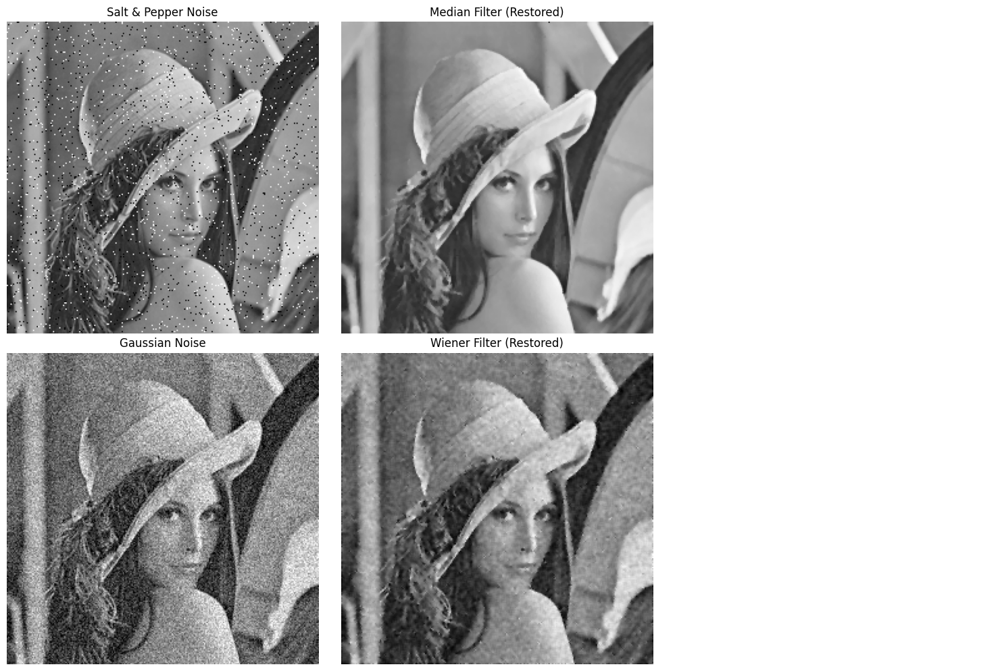

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)

# --- Noise Generation ---
# Salt & Pepper
sp_noise = np.copy(img_gray)
num_salt = np.ceil(0.02 * img_gray.size)
coords_salt = [np.random.randint(0, i - 1, int(num_salt)) for i in img_gray.shape]
sp_noise[tuple(coords_salt)] = 255
num_pepper = np.ceil(0.02 * img_gray.size)
coords_pepper = [np.random.randint(0, i - 1, int(num_pepper)) for i in img_gray.shape]
sp_noise[tuple(coords_pepper)] = 0

# Gaussian Noise
gaussian_noise = np.zeros(img_gray.shape, dtype=np.int16)
cv2.randn(gaussian_noise, 0, 25)
gaussian_noisy_img = cv2.add(img_gray, gaussian_noise, dtype=cv2.CV_8U)

# --- Restoration ---
restored_median = cv2.medianBlur(sp_noise, 3)
restored_wiener = wiener(gaussian_noisy_img.astype(np.float64), mysize=3).astype(np.uint8)

# Plotting Results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(sp_noise, cmap='gray')
axes[0, 0].set_title('Salt & Pepper Noise')
axes[0, 0].axis('off')

axes[0, 1].imshow(restored_median, cmap='gray')
axes[0, 1].set_title('Median Filter (Restored)')
axes[0, 1].axis('off')

axes[0, 2].axis('off')

axes[1, 0].imshow(gaussian_noisy_img, cmap='gray')
axes[1, 0].set_title('Gaussian Noise')
axes[1, 0].axis('off')

axes[1, 1].imshow(restored_wiener, cmap='gray')
axes[1, 1].set_title('Wiener Filter (Restored)')
axes[1, 1].axis('off')

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Practical 8: Spatial Filtering
* a. 1-D and 2-D convolution processes
* b. 3x3 Mask for Low-pass (Blurring) and High-pass (Sharpening) filters

1-D Convolution of signal [1. 2. 3. 4. 5.] with kernel [0.5 1.  0.5]:
[2. 4. 6. 8. 7.]



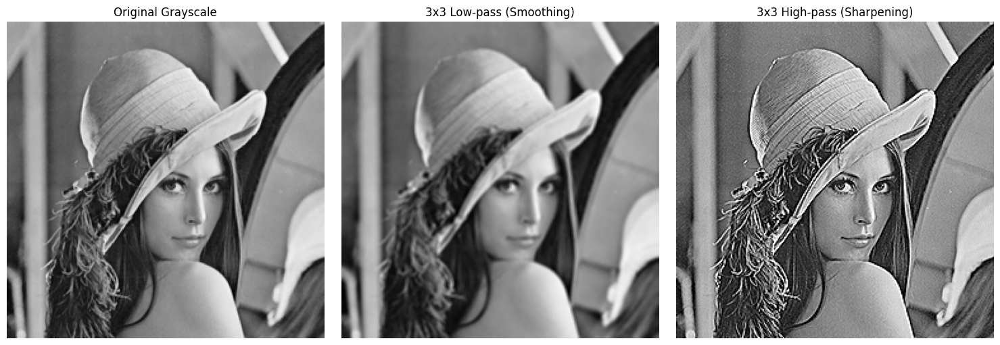

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)

# 8.a. Demonstration of 1-D & 2-D Convolution Processes
signal_1d = np.array([1, 2, 3, 4, 5], dtype=float)
kernel_1d = np.array([0.5, 1, 0.5], dtype=float)
conv_1d = np.convolve(signal_1d, kernel_1d, mode='same')
print(f"1-D Convolution of signal {signal_1d} with kernel {kernel_1d}:\n{conv_1d}\n")

# 8.b. 3x3 Masks
# Low-pass filter mask (Averaging box filter)
low_pass_mask = np.ones((3, 3), dtype=np.float32) / 9.0

# High-pass filter mask (Laplacian sharpening mask)
high_pass_mask = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]], dtype=np.float32)

low_pass_filtered = cv2.filter2D(img_gray, -1, low_pass_mask)
high_pass_filtered = cv2.filter2D(img_gray, -1, high_pass_mask)

# Plotting Results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Original Grayscale')
axes[0].axis('off')

axes[1].imshow(low_pass_filtered, cmap='gray')
axes[1].set_title('3x3 Low-pass (Smoothing)')
axes[1].axis('off')

axes[2].imshow(high_pass_filtered, cmap='gray')
axes[2].set_title('3x3 High-pass (Sharpening)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Practical 9: Image Frequency Domain Filtering
* a. Apply FFT on given image
* b. Perform Low-pass and High-pass filtering in frequency domain
* c. Apply IFFT to reconstruct image

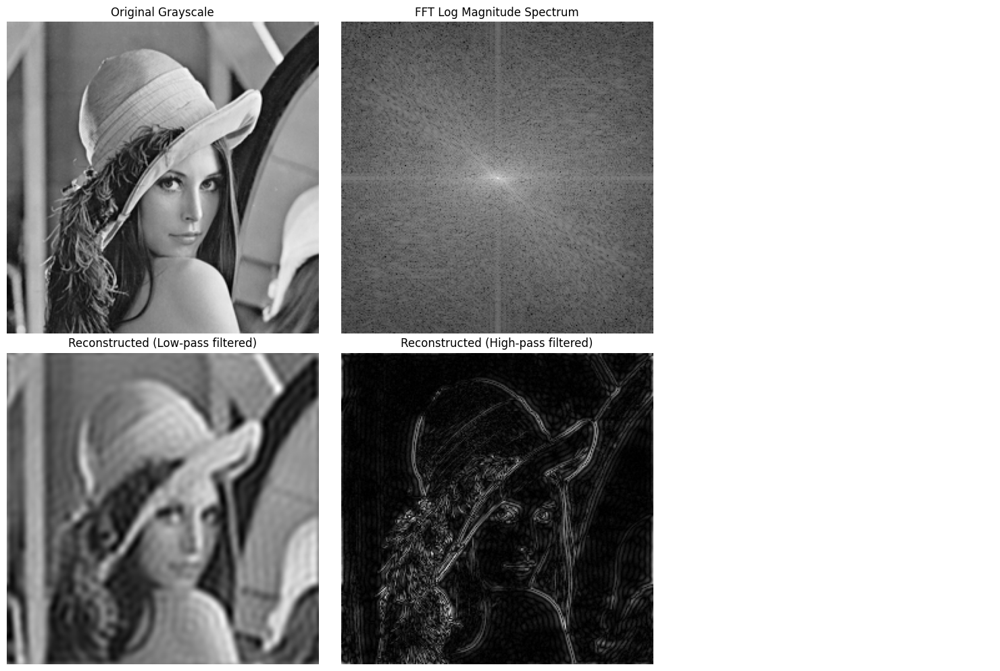

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)

# 9.a. Apply FFT on image
fft_img = np.fft.fft2(img_gray)
fft_shift = np.fft.fftshift(fft_img)
magnitude_spectrum = 20 * np.log(np.abs(fft_shift) + 1)

# Get dimensions
rows, cols = img_gray.shape
crow, ccol = rows // 2, cols // 2

# Create Masks
# Low Pass Filter (LPF) Mask
lpf_mask = np.zeros((rows, cols), np.uint8)
r_lpf = 30
cv2.circle(lpf_mask, (ccol, crow), r_lpf, 1, -1)

# High Pass Filter (HPF) Mask
hpf_mask = np.ones((rows, cols), np.uint8)
r_hpf = 30
cv2.circle(hpf_mask, (ccol, crow), r_hpf, 0, -1)

# Apply Masks and Inverse FFT (IFFT)
fshift_lpf = fft_shift * lpf_mask
f_lpf = np.fft.ifftshift(fshift_lpf)
img_lpf_reconstructed = np.abs(np.fft.ifft2(f_lpf))

fshift_hpf = fft_shift * hpf_mask
f_hpf = np.fft.ifftshift(fshift_hpf)
img_hpf_reconstructed = np.abs(np.fft.ifft2(f_hpf))

# Plotting Frequency Filtering Results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(img_gray, cmap='gray')
axes[0, 0].set_title('Original Grayscale')
axes[0, 0].axis('off')

axes[0, 1].imshow(magnitude_spectrum, cmap='gray')
axes[0, 1].set_title('FFT Log Magnitude Spectrum')
axes[0, 1].axis('off')

axes[0, 2].axis('off')

axes[1, 0].imshow(img_lpf_reconstructed, cmap='gray')
axes[1, 0].set_title('Reconstructed (Low-pass filtered)')
axes[1, 0].axis('off')

axes[1, 1].imshow(img_hpf_reconstructed, cmap='gray')
axes[1, 1].set_title('Reconstructed (High-pass filtered)')
axes[1, 1].axis('off')

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Practical 10: Edge Detection using Different Masks
* Sobel Edge Detection (Horizontal & Vertical)
* Laplacian Edge Detection
* Canny Edge Detection

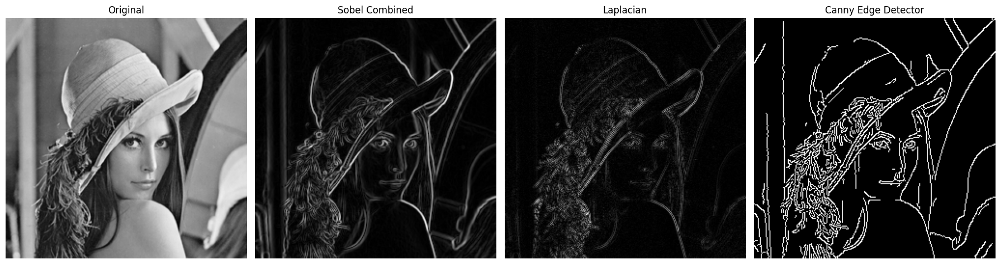

In [40]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)

# Sobel Edge Detection
sobelx = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)

# Laplacian
laplacian = cv2.Laplacian(img_gray, cv2.CV_64F)

# Canny Edge Detection
canny = cv2.Canny(img_gray, 100, 200)

# Displaying the Edge detection results
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(np.abs(sobel_combined), cmap='gray')
axes[1].set_title('Sobel Combined')
axes[1].axis('off')

axes[2].imshow(np.abs(laplacian), cmap='gray')
axes[2].set_title('Laplacian')
axes[2].axis('off')

axes[3].imshow(canny, cmap='gray')
axes[3].set_title('Canny Edge Detector')
axes[3].axis('off')

plt.tight_layout()
plt.show()

### Practical 11: Image Morphological Operations
* Erosion
* Dilation

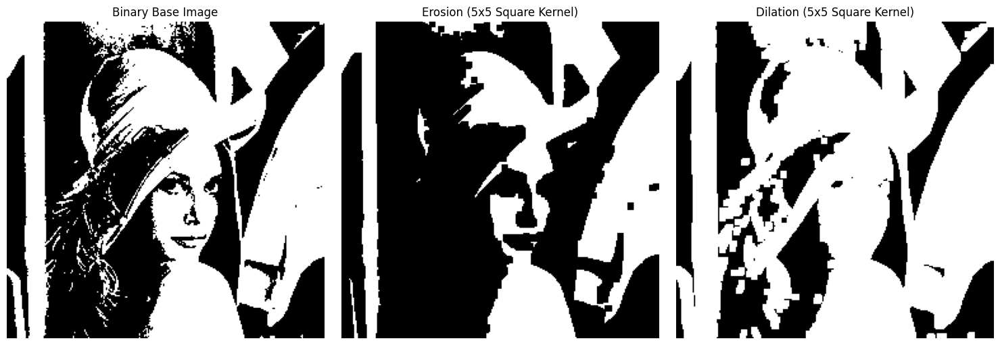

In [41]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_gray = cv2.imread('./Lenna_test_image.png', cv2.IMREAD_GRAYSCALE)

# Binary structuring element (kernel) for morphological transformations
kernel_morph = np.ones((5, 5), dtype=np.uint8)

# Convert to binary for clean demonstration
_, binary_img = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

eroded_img = cv2.erode(binary_img, kernel_morph, iterations=1)
dilated_img = cv2.dilate(binary_img, kernel_morph, iterations=1)

# Plotting Results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(binary_img, cmap='gray')
axes[0].set_title('Binary Base Image')
axes[0].axis('off')

axes[1].imshow(eroded_img, cmap='gray')
axes[1].set_title('Erosion (5x5 Square Kernel)')
axes[1].axis('off')

axes[2].imshow(dilated_img, cmap='gray')
axes[2].set_title('Dilation (5x5 Square Kernel)')
axes[2].axis('off')

plt.tight_layout()
plt.show()